In [ ]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Cornplant"

for item in os.listdir(dataset_path):
    print(item)


Corn


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Cornplant/Corn"

print(os.listdir(dataset_path))


['data']


In [ ]:
data_path = "/content/drive/MyDrive/Cornplant/Corn/data"

print(os.listdir(data_path))


['Gray_Leaf_Spot', 'Healthy', 'Common_Rust', 'Blight']


In [ ]:
import os

for class_name in os.listdir(data_path):
    class_path = os.path.join(data_path, class_name)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        print(class_name, ":", len(images), "images")



Gray_Leaf_Spot : 574 images
Healthy : 1162 images
Common_Rust : 1306 images
Blight : 1146 images


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("Classes:", train_ds.class_names)


Found 4188 files belonging to 4 classes.
Using 3351 files for training.
Found 4188 files belonging to 4 classes.
Using 837 files for validation.
Classes: ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']


In [ ]:
from tensorflow.keras.applications import VGG16

base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Classification

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(4, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,044 (56.64 MB)

 Trainable params: 132,356 (517.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Model Compile

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

VGG16 image proceccing

In [ ]:
from tensorflow.keras.applications.vgg16 import preprocess_input

train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

VGG16 Model Training

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=0.000001
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 23s 214ms/step - accuracy: 0.9388 - loss: 0.1584 - val_accuracy: 0.9152 - val_loss: 0.2335 - learning_rate: 1.0000e-04
Epoch 2/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 21s 201ms/step - accuracy: 0.9391 - loss: 0.1492 - val_accuracy: 0.9164 - val_loss: 0.2332 - learning_rate: 1.0000e-04
Epoch 3/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 20s 189ms/step - accuracy: 0.9433 - loss: 0.1465 - val_accuracy: 0.9188 - val_loss: 0.2326 - learning_rate: 1.0000e-04
Epoch 4/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 23s 222ms/step - accuracy: 0.9466 - loss: 0.1473 - val_accuracy: 0.9164 - val_loss: 0.2308 - learning_rate: 1.0000e-04
Epoch 5/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 21s 194ms/step - accuracy: 0.9526 - loss: 0.1352 - val_accuracy: 0.9200 - val_loss: 0.2292 - learning_rate: 1.0000e-04
Epoch 6/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 23s 218ms/step - accuracy: 0.9514 - loss: 0.1277 - val_accuracy: 0.9176 - val_loss: 0.2241 - learning_rate: 1.0000e-04
Epoch 7/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 21s 20

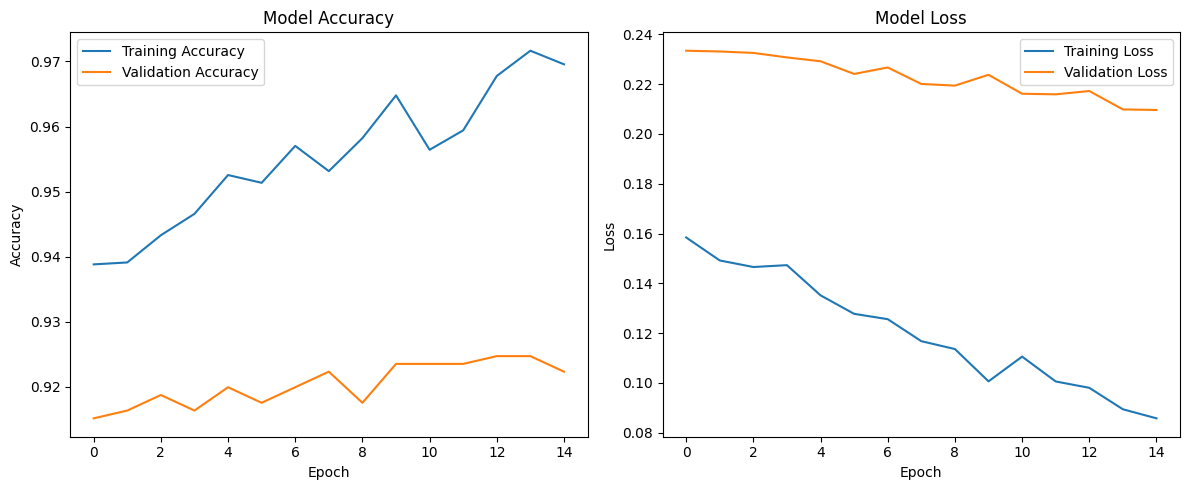

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

Prediction

In [ ]:
import numpy as np

y_true = np.concatenate([y.numpy() for x, y in val_ds])

y_pred_prob = model.predict(val_ds)

y_pred = np.argmax(y_pred_prob, axis=1)

27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 166ms/step


Classification Matrix

In [ ]:
import os

class_names = sorted([
    folder for folder in os.listdir(data_path)
    if os.path.isdir(os.path.join(data_path, folder))
])

print(class_names)

['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']


Validation dataset


In [ ]:
val_ds_eval = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    shuffle=True
)

class_names = val_ds_eval.class_names

print("Classes:", class_names)

Found 4188 files belonging to 4 classes.
Using 837 files for validation.
Classes: ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']


In [ ]:
from tensorflow.keras.applications.vgg16 import preprocess_input

val_ds_eval = val_ds_eval.map(
    lambda x, y: (preprocess_input(x), y)
)

val_ds_eval = val_ds_eval.prefetch(tf.data.AUTOTUNE)

Model Evaluation using Classification Report and Accuracy

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, accuracy_score

y_true_correct = []
y_pred_correct = []

for images, labels in val_ds_eval:
    predictions = model.predict(images, verbose=0)

    y_true_correct.extend(labels.numpy())
    y_pred_correct.extend(np.argmax(predictions, axis=1))

y_true_correct = np.array(y_true_correct)
y_pred_correct = np.array(y_pred_correct)

print(classification_report(
    y_true_correct,
    y_pred_correct,
    labels=[0, 1, 2, 3],
    target_names=class_names
))

print("Validation Accuracy:",
      accuracy_score(y_true_correct, y_pred_correct) * 100, "%")

                precision    recall  f1-score   support

        Blight       0.87      0.88      0.87       225
   Common_Rust       0.97      0.95      0.96       244
Gray_Leaf_Spot       0.81      0.79      0.80       126
       Healthy       0.99      1.00      0.99       242

      accuracy                           0.92       837
     macro avg       0.91      0.91      0.91       837
  weighted avg       0.92      0.92      0.92       837

Validation Accuracy: 92.23416965352449 %


Confution Matrix


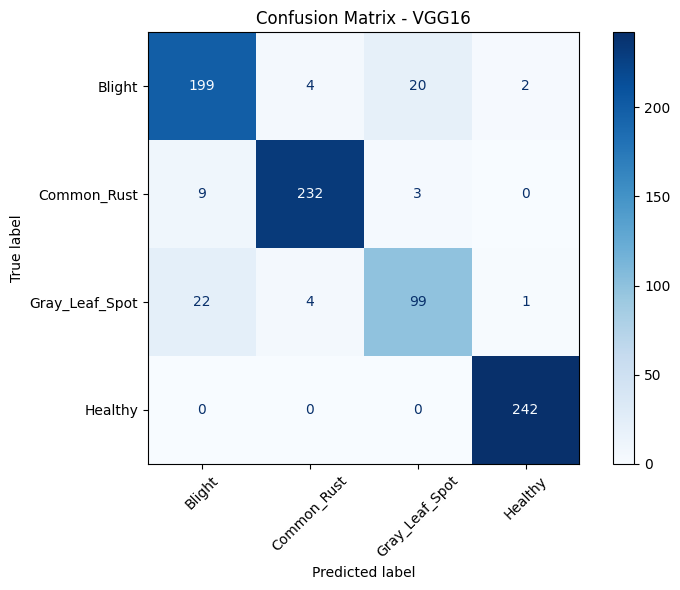

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true_correct,
    y_pred_correct,
    labels=[0, 1, 2, 3]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap='Blues', xticks_rotation=45, ax=ax)

plt.title('Confusion Matrix - VGG16')
plt.tight_layout()
plt.show()

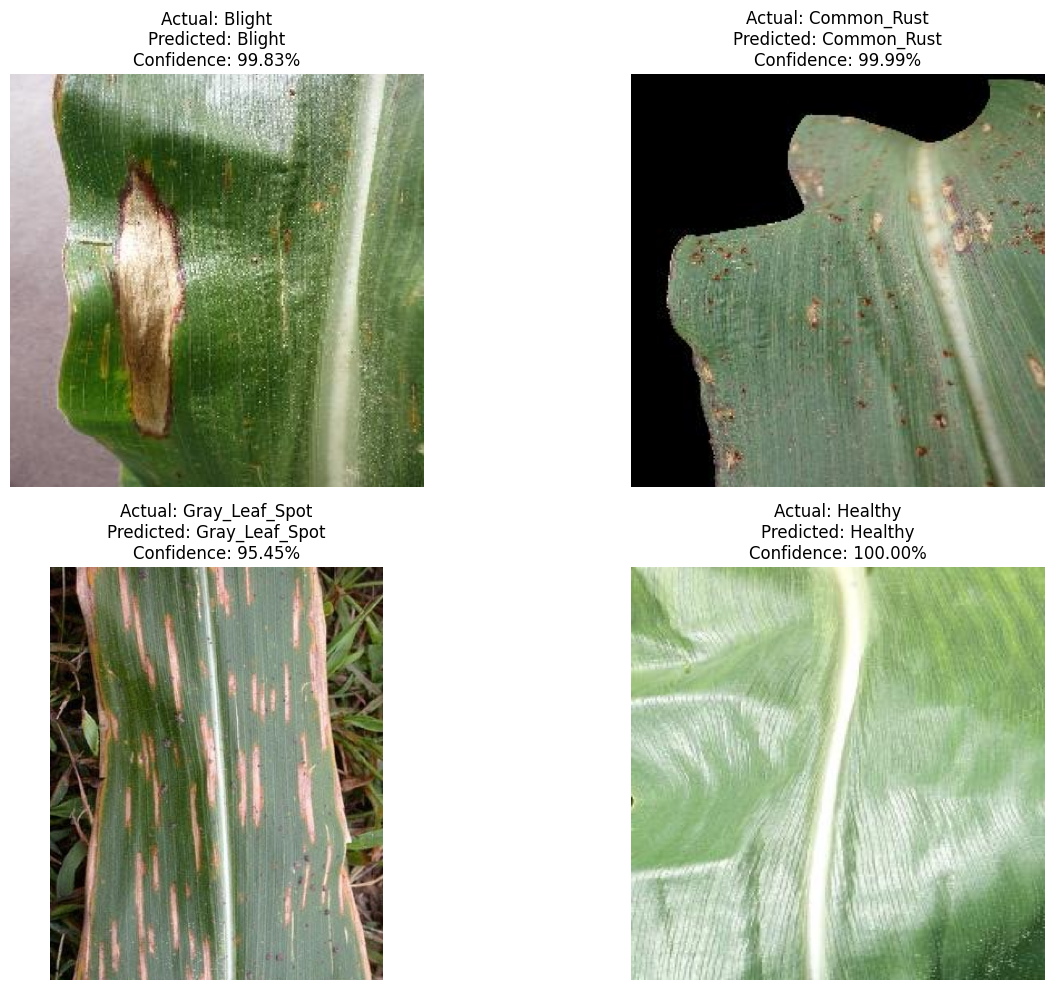

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.vgg16 import preprocess_input

class_names = ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']

data_path = "/content/drive/MyDrive/Cornplant/Corn/data"

plt.figure(figsize=(14, 10))

for i, class_name in enumerate(class_names):

    class_path = os.path.join(data_path, class_name)

    img_name = random.choice(os.listdir(class_path))
    img_path = os.path.join(class_path, img_name)

    img = image.load_img(img_path, target_size=(224, 224))

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    prediction = model.predict(img_array, verbose=0)

    predicted_class = class_names[np.argmax(prediction)]
    confidence = np.max(prediction) * 100

    plt.subplot(2, 2, i+1)
    plt.imshow(image.load_img(img_path))
    plt.title(f"Actual: {class_name}\nPredicted: {predicted_class}\nConfidence: {confidence:.2f}%")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
model.save('/content/drive/MyDrive/Cornplant/VGG16_Corn_Model.keras')

print("Model saved successfully")

Model saved successfully


In [ ]:
from tensorflow.keras.models import load_model

loaded_model = load_model(
    '/content/drive/MyDrive/Cornplant/VGG16_Corn_Model.keras'
)

print("Model loaded successfully")

Model loaded successfully


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 711ms/step


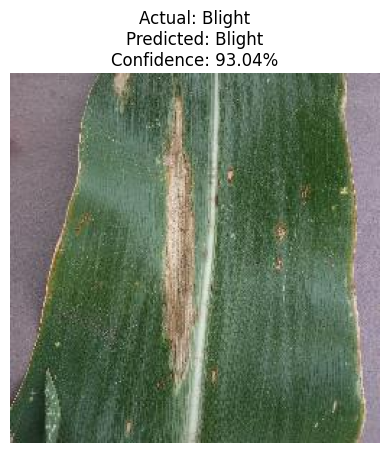

Actual Class: Blight
Predicted Class: Blight
Confidence: 93.04%


In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.vgg16 import preprocess_input

class_names = ['Blight', 'Common_Rust', 'Gray_Leaf_Spot', 'Healthy']

test_class = random.choice(class_names)

class_path = os.path.join(data_path, test_class)

img_name = random.choice(os.listdir(class_path))
img_path = os.path.join(class_path, img_name)

img = image.load_img(img_path, target_size=(224, 224))

img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

prediction = loaded_model.predict(img_array)

predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction) * 100

plt.imshow(image.load_img(img_path))
plt.title(
    f"Actual: {test_class}\nPredicted: {predicted_class}\nConfidence: {confidence:.2f}%"
)
plt.axis('off')
plt.show()

print("Actual Class:", test_class)
print("Predicted Class:", predicted_class)
print("Confidence:", f"{confidence:.2f}%")